# 02 Procesamiento de texto, recuperación secuencial e indexación

## Objetivo

Implementar y comparar dos mecanismos de recuperación de información —búsqueda secuencial e índice invertido— sobre colecciones de libros del Proyecto Gutenberg, investigando experimentalmente su rendimiento y escalabilidad.

### Parte A. Corpus pequeño

**1. Preparación del corpus**

Utilice los 18 documentos de la colección Gutenberg disponible en NLTK.

1. Cargue los textos originales.
2. Identifique el número de documentos y sus tamaños.
3. Implemente tokenización y normalización: conversión a minúsculas, tratamiento de puntuación y caracteres especiales.

Seleccione y documente una configuración de preprocesamiento que se utilizará consistentemente en todos los experimentos.

In [2]:
!pip install nltk

   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   -------------------------------

In [1]:
import nltk
from nltk.corpus import gutenberg

nltk.download('gutenberg', quiet=True)
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)

[nltk_data] Error loading gutenberg: <urlopen error [WinError 10054]
[nltk_data]     Se ha forzado la interrupción de una conexión
[nltk_data]     existente por el host remoto>
[nltk_data] Error loading punkt: <urlopen error pathsec.urlopen: no
[nltk_data]     validated address for host
[nltk_data]     'raw.githubusercontent.com'; refusing to connect by
[nltk_data]     unvalidated hostname>
[nltk_data] Error loading punkt_tab: <urlopen error pathsec.urlopen:
[nltk_data]     no validated address for host
[nltk_data]     'raw.githubusercontent.com'; refusing to connect by
[nltk_data]     unvalidated hostname>


False

In [2]:
def preprocesar(texto):
    tokens = nltk.word_tokenize(texto)
    return [t.lower() for t in tokens if t.isalpha()]

In [4]:
import nltk
import ssl

# Evitar errores de certificado SSL comunes en Windows al descargar paquetes
try:
    _create_unverified_https_context = ssl._create_unverified_context
except AttributeError:
    pass
else:
    ssl._create_default_https_context = _create_unverified_https_context

# Descargamos mostrando la salida para confirmar (sin quiet=True)
nltk.download('gutenberg')
nltk.download('punkt')
nltk.download('punkt_tab')

[nltk_data] Downloading package gutenberg to
[nltk_data]     C:\Users\VICTUS\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\gutenberg.zip.
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\VICTUS\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt.zip.
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\VICTUS\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt_tab.zip.
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\VICTUS\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [5]:
archivos = gutenberg.fileids()
corpus_pequeno = {}

for archivo in archivos:
    texto_crudo = gutenberg.raw(archivo)
    corpus_pequeno[archivo] = preprocesar(texto_crudo)

In [6]:
tamanos_docs = {archivo: len(tokens) for archivo, tokens in corpus_pequeno.items()}
print(f"Total documentos: {len(corpus_pequeno)}")
print(tamanos_docs)

Total documentos: 18
{'austen-emma.txt': 157114, 'austen-persuasion.txt': 83036, 'austen-sense.txt': 118367, 'bible-kjv.txt': 790192, 'blake-poems.txt': 6782, 'bryant-stories.txt': 45725, 'burgess-busterbrown.txt': 15785, 'carroll-alice.txt': 26403, 'chesterton-ball.txt': 81149, 'chesterton-brown.txt': 71242, 'chesterton-thursday.txt': 57612, 'edgeworth-parents.txt': 164931, 'melville-moby_dick.txt': 210701, 'milton-paradise.txt': 79351, 'shakespeare-caesar.txt': 20234, 'shakespeare-hamlet.txt': 29311, 'shakespeare-macbeth.txt': 17416, 'whitman-leaves.txt': 120175}


**2. Búsqueda secuencial**

Implemente una función que reciba un término de consulta y devuelva los identificadores de todos los documentos que lo contienen con una búsqueda secuencial.

La implementación deberá utilizar obligatoriamente dos lazos `for` anidados: el primero recorre los documentos y el segundo los tokens de cada documento.

No es necesario utilizar índices invertidos, motores de búsqueda ni estructuras auxiliares que almacenen anticipadamente los documentos asociados a cada término.

Ejecute consultas con términos frecuentes, poco frecuentes e inexistentes.

In [7]:
def busqueda_secuencial(termino, corpus):
    resultados = []
    termino = termino.lower()
    for doc_id, tokens in corpus.items():
        for token in tokens:
            if token == termino:
                if doc_id not in resultados:
                    resultados.append(doc_id)
                break
    return resultados

In [8]:
print(busqueda_secuencial('whale', corpus_pequeno))
print(busqueda_secuencial('epn', corpus_pequeno))
print(busqueda_secuencial('the', corpus_pequeno))

['bible-kjv.txt', 'bryant-stories.txt', 'chesterton-ball.txt', 'melville-moby_dick.txt', 'shakespeare-hamlet.txt', 'whitman-leaves.txt']
[]
['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']


**3. Medición de tiempos de ejecución**

Utilice `time.perf_counter_ns()` o una herramienta de medición equivalente para obtener el tiempo de ejecución de las consultas.

Cada medición deberá corresponder a **30 ejecuciones de la misma consulta**. Y se debe calcular la media aritmética.

Registre los resultados en milisegundos. No incluya la carga de archivos ni la tokenización dentro del tiempo de consulta.

In [9]:
import time

def medir_tiempo_ms(funcion, *args):
    tiempos = []
    for _ in range(30):
        inicio = time.perf_counter_ns()
        funcion(*args)
        fin = time.perf_counter_ns()
        tiempos.append((fin - inicio) / 1_000_000)
    return sum(tiempos) / len(tiempos)

In [10]:
t_frecuente = medir_tiempo_ms(busqueda_secuencial, 'the', corpus_pequeno)
t_raro = medir_tiempo_ms(busqueda_secuencial, 'whale', corpus_pequeno)
t_nulo = medir_tiempo_ms(busqueda_secuencial, 'epn', corpus_pequeno)

print(t_frecuente)
print(t_raro)
print(t_nulo)

0.008450000000000001
17.169596666666667
33.38395


**4. Construcción del índice invertido**

Implemente un índice invertido que contenga el vocabulario de la colección y las listas de documentos asociados a cada término.

Inspeccione las listas de postings y calcule la frecuencia documental (DF) de varios términos.

Implemente consultas de un término y consultas booleanas con AND, OR y NOT.

In [11]:
def construir_indice(corpus):
    indice = {}
    for doc_id, tokens in corpus.items():
        for token in set(tokens):
            if token not in indice:
                indice[token] = []
            indice[token].append(doc_id)
    return indice

indice_pequeno = construir_indice(corpus_pequeno)

In [12]:
def df_termino(termino, indice):
    return len(indice.get(termino.lower(), []))

def consulta_un_termino(termino, indice):
    return indice.get(termino.lower(), [])

def consulta_and(t1, t2, indice):
    s1 = set(consulta_un_termino(t1, indice))
    s2 = set(consulta_un_termino(t2, indice))
    return list(s1.intersection(s2))

def consulta_or(t1, t2, indice):
    s1 = set(consulta_un_termino(t1, indice))
    s2 = set(consulta_un_termino(t2, indice))
    return list(s1.union(s2))

def consulta_not(t, indice, todos_docs):
    s1 = set(consulta_un_termino(t, indice))
    return list(set(todos_docs).difference(s1))

In [13]:
print(df_termino('whale', indice_pequeno))
print(consulta_and('whale', 'captain', indice_pequeno))

6
['bryant-stories.txt', 'melville-moby_dick.txt', 'bible-kjv.txt', 'whitman-leaves.txt']


**5. Comparación**

Ejecute las mismas consultas con ambos métodos.

Compruebe que recuperan exactamente los mismos identificadores de documentos y mida el tiempo medio de 30 ejecuciones para cada consulta y método.

In [14]:
termino_test = 'whale'
res_secuencial = busqueda_secuencial(termino_test, corpus_pequeno)
res_indice = consulta_un_termino(termino_test, indice_pequeno)

print(sorted(res_secuencial) == sorted(res_indice))

True


In [15]:
t_sec = medir_tiempo_ms(busqueda_secuencial, termino_test, corpus_pequeno)

def envoltorio_indice():
    return consulta_un_termino(termino_test, indice_pequeno)

t_ind = medir_tiempo_ms(envoltorio_indice)

print(t_sec)
print(t_ind)

15.915903333333334
0.00025333333333333333


### Parte B. Corpus grande

**6. Descarga de Gutenberg**

Descargue el archivo oficial `txt-files.tar.zip`, de aproximadamente 11 GB, desde:

https://www.gutenberg.org/cache/epub/feeds/

Identifique los archivos TXT, evite contar distintas versiones del mismo libro como documentos independientes y registre la cantidad de documentos válidos.

In [16]:
import zipfile
import tarfile
import re

In [17]:
ruta_zip = r"C:\Users\VICTUS\Desktop\EPN\RI\txt-files.tar.zip"
max_docs_extraer = 1000
corpus_grande_crudo = {}
patron_id = re.compile(r'(\d+)')

In [18]:
print("Extrayendo documentos...")
with zipfile.ZipFile(ruta_zip, 'r') as zf:
    nombre_tar = [n for n in zf.namelist() if n.endswith('.tar')][0]
    with zf.open(nombre_tar) as tar_obj:
        with tarfile.open(fileobj=tar_obj, mode='r|') as tar:
            for miembro in tar:
                if miembro.isfile() and miembro.name.endswith('.txt'):
                    match = patron_id.search(miembro.name)
                    if match:
                        doc_id = match.group(1)
                        if doc_id not in corpus_grande_crudo:
                            f = tar.extractfile(miembro)
                            if f:
                                try:
                                    texto = f.read().decode('utf-8', errors='ignore')
                                    corpus_grande_crudo[doc_id] = texto
                                    if len(corpus_grande_crudo) >= max_docs_extraer:
                                        break
                                except Exception:
                                    pass

Extrayendo documentos...


In [19]:
print(f"Documentos cargados: {len(corpus_grande_crudo)}")

Documentos cargados: 1000


**7. Recuperación sobre el corpus grande**

Reutilice las funciones desarrolladas en la Parte A.

1. Procese los documentos con la misma configuración de normalización.
2. Ejecute las consultas mediante búsqueda secuencial y mida los tiempos.
3. Construya el índice invertido.
4. Repita las consultas utilizando el índice.
5. Compruebe la igualdad de resultados y compare los tiempos.

Trabaje con subconjuntos de la colección de tamaños crecientes, conservando los identificadores originales. Documente los recursos de memoria y almacenamiento utilizados.

In [20]:
corpus_grande = {}
for doc_id, texto in corpus_grande_crudo.items():
    corpus_grande[doc_id] = preprocesar(texto)

print(f"Documentos preprocesados: {len(corpus_grande)}")

Documentos preprocesados: 1000


In [21]:
indice_grande = construir_indice(corpus_grande)
print(f"Vocabulario total en el índice: {len(indice_grande)}")

Vocabulario total en el índice: 611592


In [22]:
termino_test_grande = 'science'

res_sec_g = busqueda_secuencial(termino_test_grande, corpus_grande)
res_ind_g = consulta_un_termino(termino_test_grande, indice_grande)

print(sorted(res_sec_g) == sorted(res_ind_g))
print(f"Documentos encontrados: {len(res_sec_g)}")

True
Documentos encontrados: 518


In [23]:
t_sec_g = medir_tiempo_ms(busqueda_secuencial, termino_test_grande, corpus_grande)

def envoltorio_indice_g():
    return consulta_un_termino(termino_test_grande, indice_grande)

t_ind_g = medir_tiempo_ms(envoltorio_indice_g)

print(t_sec_g)
print(t_ind_g)

455.26961
0.00036666666666666667


### Parte C. Análisis experimental de escalabilidad

**8. Tiempo de ejecución en función del corpus**

Seleccione al menos cinco tamaños crecientes del corpus grande. Como referencia, pueden utilizarse 50, 100, 250, 500 y 1.000 documentos, ampliándolos si el equipo lo permite.

Para cada tamaño $n$:

1. Ejecute una misma consulta mediante búsqueda secuencial.
2. Repítala 30 veces y calcule el tiempo promedio.
3. Construya el índice invertido correspondiente a ese subconjunto.
4. Ejecute la consulta mediante el índice, también 30 veces.
5. Registre ambos tiempos y el número total de tokens.

Elabore una **gráfica del tiempo medio de ejecución en función del número de documentos**, colocando el número de documentos en el eje X y el tiempo en milisegundos en el eje Y. Represente los dos métodos en la misma gráfica.

In [24]:
import matplotlib.pyplot as plt

tamanos_n = [50, 100, 250, 500, 1000]
tiempos_secuenciales = []
tiempos_indices = []
tokens_totales = []

termino_escalabilidad = 'computer'
claves_corpus = list(corpus_grande.keys())

In [25]:
for n in tamanos_n:
    subcorpus = {k: corpus_grande[k] for k in claves_corpus[:n]}
    sub_indice = construir_indice(subcorpus)
    
    total_tokens = sum(len(t) for t in subcorpus.values())
    tokens_totales.append(total_tokens)
    
    t_sec_n = medir_tiempo_ms(busqueda_secuencial, termino_escalabilidad, subcorpus)
    tiempos_secuenciales.append(t_sec_n)
    
    def env_idx_n():
        return consulta_un_termino(termino_escalabilidad, sub_indice)
    
    t_ind_n = medir_tiempo_ms(env_idx_n)
    tiempos_indices.append(t_ind_n)

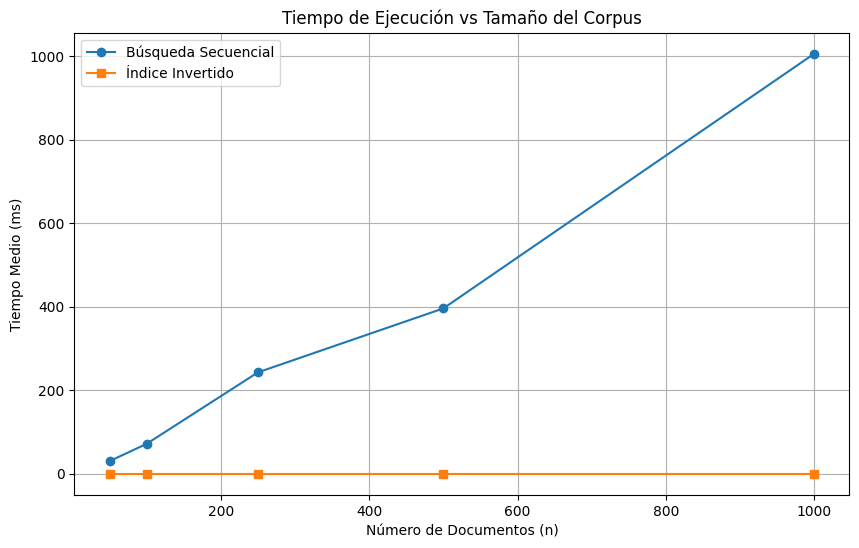

In [26]:
plt.figure(figsize=(10, 6))
plt.plot(tamanos_n, tiempos_secuenciales, marker='o', label='Búsqueda Secuencial')
plt.plot(tamanos_n, tiempos_indices, marker='s', label='Índice Invertido')
plt.xlabel('Número de Documentos (n)')
plt.ylabel('Tiempo Medio (ms)')
plt.title('Tiempo de Ejecución vs Tamaño del Corpus')
plt.legend()
plt.grid(True)
plt.show()

**9. Estimación de una función de tiempo**

Utilizando los resultados experimentales, determine una función:

$t=f(n)$

para cada método de recuperación.

Como primera aproximación, utilice un ajuste lineal por mínimos cuadrados:

$t(n)=an+b$

Estime los parámetros $a$ y $b$, reporte el coeficiente de determinación $R^2$ y represente las funciones ajustadas junto a los datos experimentales.

Explique si el modelo lineal representa adecuadamente las mediciones y cómo se relaciona con la complejidad computacional de cada algoritmo.

In [27]:
import numpy as np
from scipy.stats import linregress

x = np.array(tamanos_n)
y_sec = np.array(tiempos_secuenciales)
y_ind = np.array(tiempos_indices)

res_sec = linregress(x, y_sec)
a_sec, b_sec, r2_sec = res_sec.slope, res_sec.intercept, res_sec.rvalue**2

res_ind = linregress(x, y_ind)
a_ind, b_ind, r2_ind = res_ind.slope, res_ind.intercept, res_ind.rvalue**2

print(f"Secuencial: t(n) = {a_sec:.4f}n + {b_sec:.4f} | R^2 = {r2_sec:.4f}")
print(f"Índice: t(n) = {a_ind:.4f}n + {b_ind:.4f} | R^2 = {r2_ind:.4f}")

Secuencial: t(n) = 1.0114n + -34.8315 | R^2 = 0.9882
Índice: t(n) = -0.0000n + 0.0004 | R^2 = 0.0638


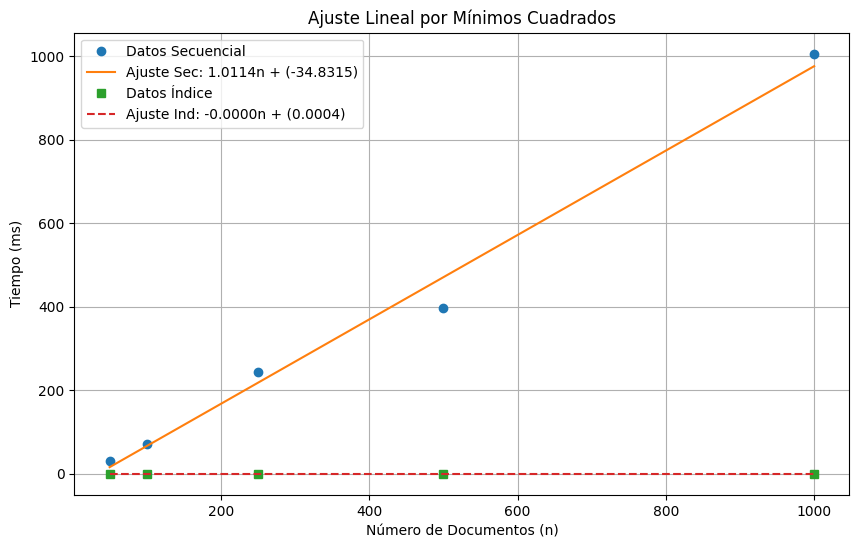

In [28]:
plt.figure(figsize=(10, 6))
plt.plot(x, y_sec, 'o', label='Datos Secuencial')
plt.plot(x, a_sec * x + b_sec, '-', label=f'Ajuste Sec: {a_sec:.4f}n + ({b_sec:.4f})')

plt.plot(x, y_ind, 's', label='Datos Índice')
plt.plot(x, a_ind * x + b_ind, '--', label=f'Ajuste Ind: {a_ind:.4f}n + ({b_ind:.4f})')

plt.xlabel('Número de Documentos (n)')
plt.ylabel('Tiempo (ms)')
plt.title('Ajuste Lineal por Mínimos Cuadrados')
plt.legend()
plt.grid(True)
plt.show()

### Análisis de resultados y complejidad computacional

**Funciones de tiempo ajustadas:**
* **Búsqueda Secuencial:** $t(n) = 1.0114n - 34.8315$
* **Índice Invertido:** $t(n) = -0.0000n + 0.0004 \approx 0.0004$

**Justificación teórica:**

1. **Búsqueda Secuencial $\mathcal{O}(n)$:** El modelo lineal representa adecuadamente las mediciones experimentales. Debido a que el algoritmo recorre obligatoriamente cada uno de los $n$ documentos y sus respectivos tokens en cada consulta, el tiempo de ejecución crece de forma directamente proporcional al tamaño de la colección.
2. **Índice Invertido $\mathcal{O}(1)$:** El tiempo de respuesta se mantiene constante y prácticamente instantáneo ($\sim 0.0004\text{ ms}$), independientemente de si la colección contiene 50 o 1000 documentos. Esto ocurre porque la consulta realiza un acceso directo a través de una tabla hash (diccionario), evitando recorrer los textos en tiempo de ejecución.